# Predicting Hotel Booking Cancellations
**ADS-505 | Team 7**  
Mitchell Capp, Ryan Elliott, and Selin Karadag

https://github.com/relliott1/ADS-505-Hotel-Cancellations-Project

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.metrics import precision_score, recall_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score
)

## Problem Statement

Hotel booking cancellations make occupancy and revenue harder to forecast
and can leave hotels with limited time to resell rooms. This project
examines which booking characteristics are associated with cancellation
and how well classification models can identify reservations at higher
risk.

We compare K-nearest neighbors, logistic regression, decision tree, and
random forest models to predict cancellation. The analysis considers
differences between city and resort hotels and evaluates the tradeoff
between catching more cancellations and incorrectly flagging bookings
that would be honored. The goal is to provide evidence that reservation
and revenue-management teams could use to prioritize follow-up, rather
than assume that predictive performance alone translates into fewer
cancellations.

## Data Description

We use the Hotel Booking Demand dataset available on Kaggle. The raw
dataset contains 119,390 bookings and 32 variables from one city hotel
and one resort hotel, with arrival dates spanning July 2015 through
August 2017. Each row represents a booking.

The predictors include numerical and categorical booking attributes,
such as lead time, length of stay, guest counts, market segment,
distribution channel, deposit type, reserved room type, average daily
rate (ADR), previous cancellations, and special requests. The binary
target, `is_canceled`, identifies canceled bookings as 1 and bookings
that were not canceled as 0.

Before modeling, we assess missing values, repeated records, unusual
guest counts, stay lengths, and room rates. We exclude
`reservation_status` and `reservation_status_date` from the predictors
because they contain outcome information and would introduce target
leakage. Feature selection also considers whether information would
be available at the intended prediction time.

**Data source:** [Hotel Booking Demand - Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)

Load Dataset

In [2]:
DATA_PATH = "hotel_bookings.csv"
FIG_DIR = "eda_figures"
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

TARGET = "is_canceled"


def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150)
    plt.show()

In [3]:
#Load and first look
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print(df.dtypes)
df.head()

Shape: (119390, 32)
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent         

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
#Data quality: missing values, duplicates, odd records
missing = (df.isna().mean() * 100).round(2)
print("Missing % (only columns with missing values):")
print(missing[missing > 0].sort_values(ascending=False))

print("\nExact duplicate rows:", df.duplicated().sum())

total_guests = df["adults"] + df["children"].fillna(0) + df["babies"]
total_nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
print("Bookings with zero guests:", (total_guests == 0).sum())
print("Bookings with zero nights:", (total_nights == 0).sum())
print("Bookings with ADR <= 0:", (df["adr"] <= 0).sum())
print("Bookings with ADR > 1000:", (df["adr"] > 1000).sum())

Missing % (only columns with missing values):
company    94.31
agent      13.69
country     0.41
dtype: float64

Exact duplicate rows: 31994
Bookings with zero guests: 180
Bookings with zero nights: 715
Bookings with ADR <= 0: 1960
Bookings with ADR > 1000: 1


In [5]:
#Leakage check: fields that reveal the outcome
# reservation_status maps directly onto the target, so it must NOT be a predictor.
print(pd.crosstab(df["reservation_status"], df[TARGET]))

LEAKY = ["reservation_status", "reservation_status_date"]

# Fields finalized after booking (or only at check-in). Discuss these in your
# report; for a booking-time model you would normally drop them.
POST_BOOKING = ["assigned_room_type", "booking_changes",
                "days_in_waiting_list", "required_car_parking_spaces"]

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207


In [6]:
#Light cleaning for EDA (creates a copy; raw df is untouched)
d = df.drop(columns=LEAKY).copy()

d["children"] = d["children"].fillna(0)
d["country"] = d["country"].fillna("Unknown")
d["agent"] = d["agent"].fillna(0).astype(int).astype(str)      # 0 = no agent
d["company"] = d["company"].notna().astype(int)                # 1 = has company

# Engineered features
d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
d["total_guests"] = d["adults"] + d["children"] + d["babies"]
d["room_mismatch"] = (d["reserved_room_type"] != d["assigned_room_type"]).astype(int)

month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
d["arrival_date_month"] = pd.Categorical(d["arrival_date_month"],
                                         categories=month_order, ordered=True)

# Flag (don't delete yet) the odd records so the team can decide together
d["flag_odd"] = ((d["total_guests"] == 0) | (d["total_nights"] == 0)
                 | (d["adr"] <= 0) | (d["adr"] > 1000)).astype(int)
print("Flagged odd records:", d["flag_odd"].sum())

Flagged odd records: 1992


Overall cancellation rate: 37.0%


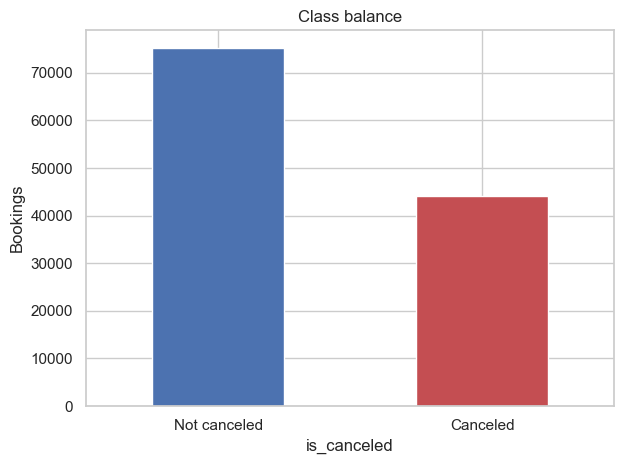

In [7]:
#Target overview
rate = d[TARGET].mean()
print(f"Overall cancellation rate: {rate:.1%}")

ax = d[TARGET].value_counts().sort_index().plot(kind="bar", color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["Not canceled", "Canceled"], rotation=0)
ax.set_ylabel("Bookings")
ax.set_title("Class balance")
save("01_class_balance")

In [8]:
#Helper: cancellation rate by a categorical column
def cancel_rate_by(col, data=d, min_count=0, top=None, figsize=(8, 4), name=None):
    g = (data.groupby(col, observed=True)[TARGET]
             .agg(rate="mean", n="size").reset_index())
    g = g[g["n"] >= min_count]
    if top:
        g = g.sort_values("n", ascending=False).head(top)
    g = g.sort_values("rate", ascending=False) if not hasattr(data[col], "cat") else g

    fig, ax = plt.subplots(figsize=figsize)
    sns.barplot(data=g, x=col, y="rate", ax=ax, color="#4C72B0")
    ax.axhline(rate, color="red", ls="--", label=f"Overall ({rate:.0%})")
    ax.set_ylabel("Cancellation rate")
    ax.set_title(f"Cancellation rate by {col}")
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.legend()
    save(name or f"rate_by_{col}")
    return g

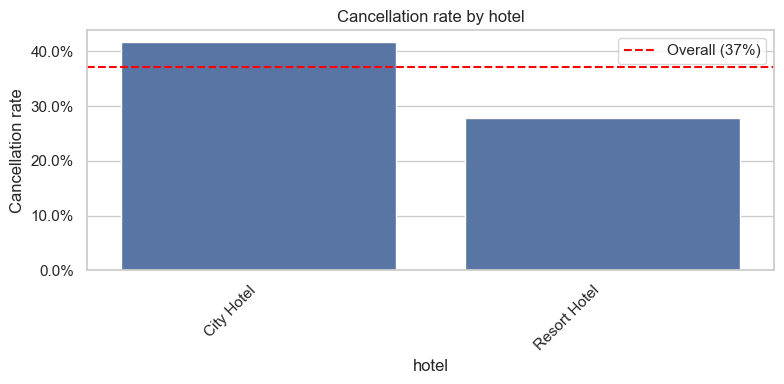

          hotel      rate      n
0    City Hotel  0.417270  79330
1  Resort Hotel  0.277634  40060 



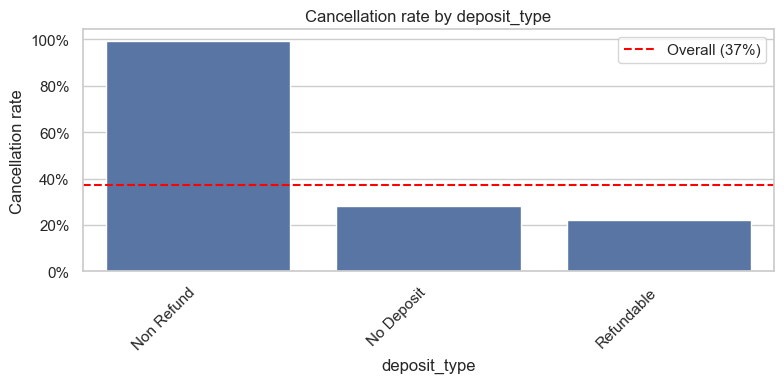

  deposit_type      rate       n
1   Non Refund  0.993624   14587
0   No Deposit  0.283770  104641
2   Refundable  0.222222     162 



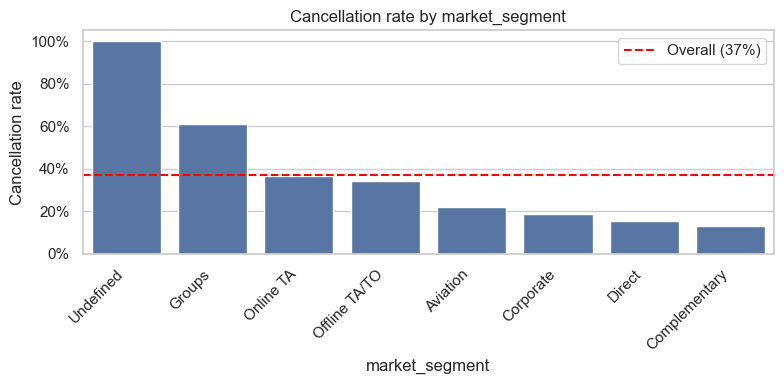

  market_segment      rate      n
7      Undefined  1.000000      2
4         Groups  0.610620  19811
6      Online TA  0.367211  56477
5  Offline TA/TO  0.343160  24219
0       Aviation  0.219409    237
2      Corporate  0.187347   5295
3         Direct  0.153419  12606
1  Complementary  0.130552    743 



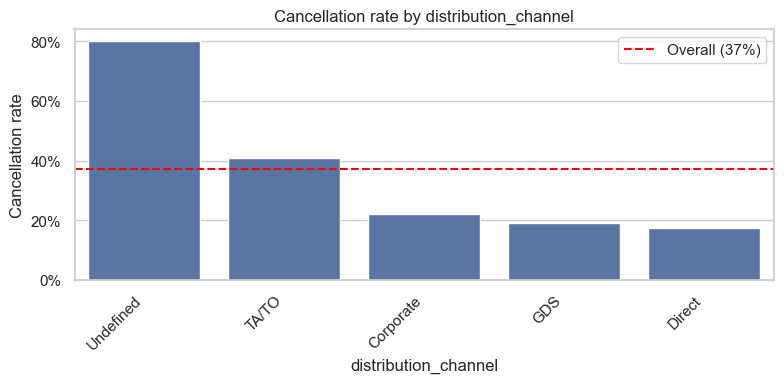

  distribution_channel      rate      n
4            Undefined  0.800000      5
3                TA/TO  0.410259  97870
0            Corporate  0.220758   6677
2                  GDS  0.191710    193
1               Direct  0.174599  14645 



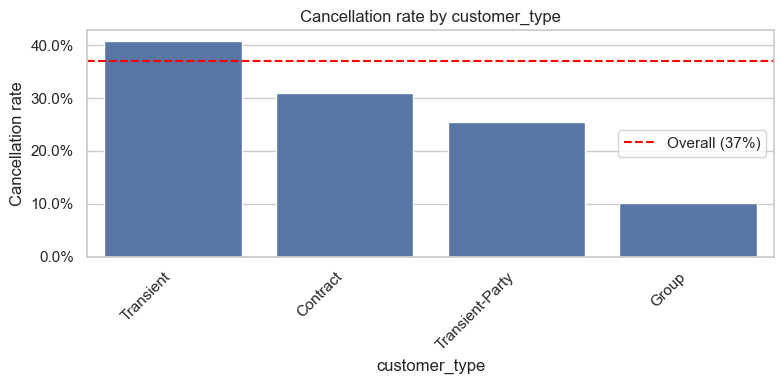

     customer_type      rate      n
2        Transient  0.407463  89613
0         Contract  0.309617   4076
3  Transient-Party  0.254299  25124
1            Group  0.102253    577 



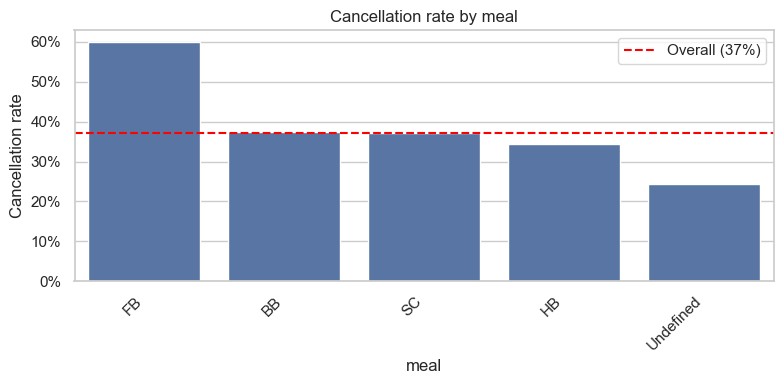

        meal      rate      n
1         FB  0.598997    798
0         BB  0.373849  92310
3         SC  0.372394  10650
2         HB  0.344603  14463
4  Undefined  0.244654   1169 



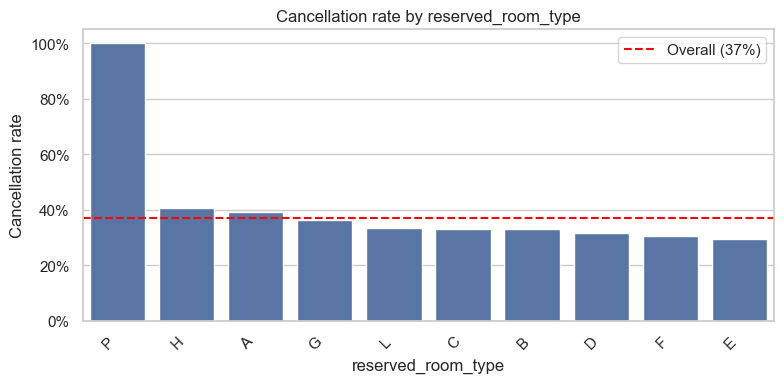

  reserved_room_type      rate      n
9                  P  1.000000     12
7                  H  0.407654    601
0                  A  0.391074  85994
6                  G  0.364374   2094
8                  L  0.333333      6
2                  C  0.330472    932
1                  B  0.329159   1118
3                  D  0.317796  19201
5                  F  0.303763   2897
4                  E  0.292884   6535 



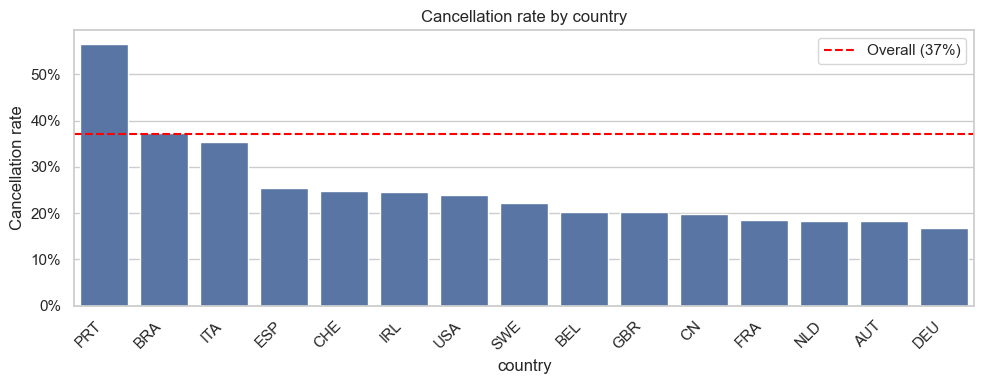

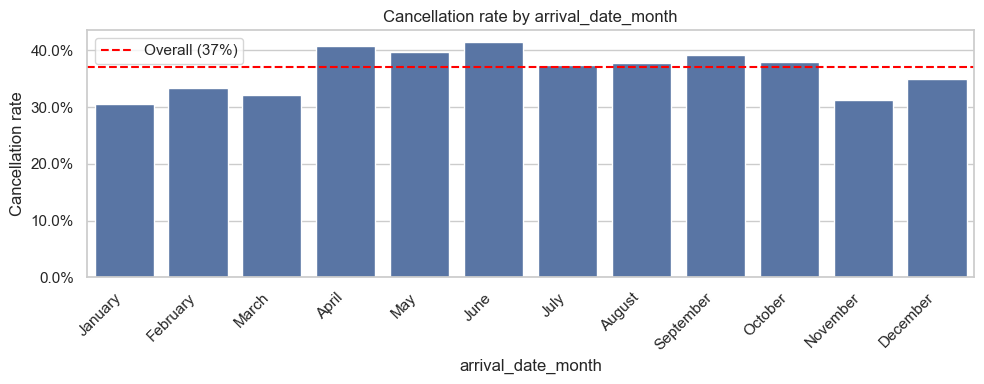

,arrival_date_month,rate,n
0,January,0.304773,5929
1,February,0.334160,8068
2,March,0.321523,9794
3,April,0.407972,11089
4,May,0.396658,11791
5,June,0.414572,10939
6,July,0.374536,12661
7,August,0.377531,13877
8,September,0.391702,10508
9,October,0.380466,11160


In [9]:
#Categorical drivers
for col in ["hotel", "deposit_type", "market_segment", "distribution_channel",
            "customer_type", "meal", "reserved_room_type"]:
    print(cancel_rate_by(col, name=f"02_{col}"), "\n")

# Country (top 15 by volume) and arrival month
cancel_rate_by("country", top=15, figsize=(10, 4), name="02_country")
cancel_rate_by("arrival_date_month", figsize=(10, 4), name="02_month")


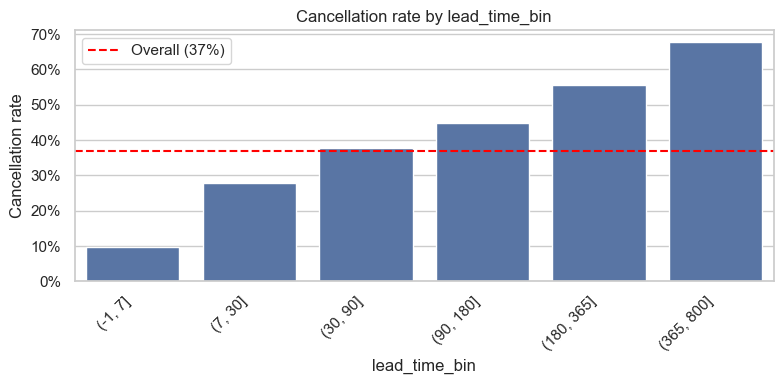

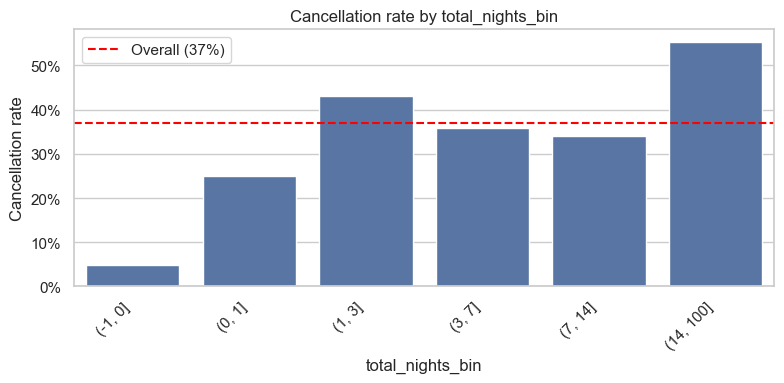

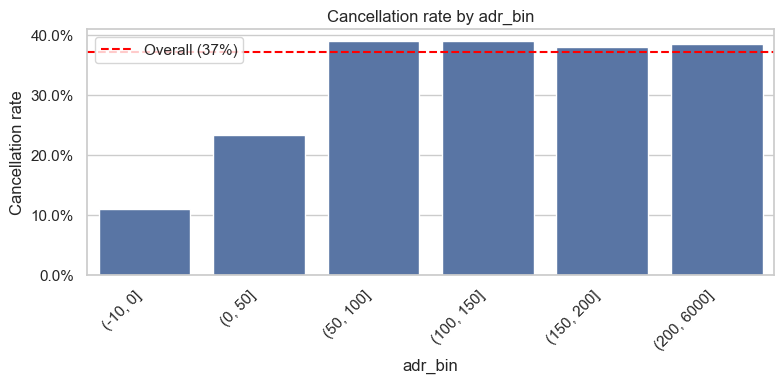

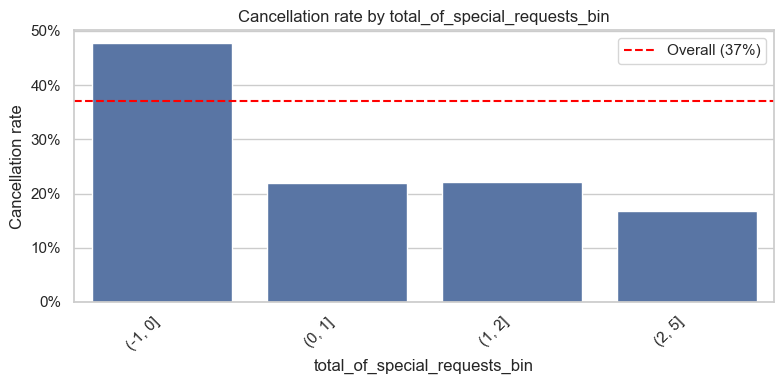

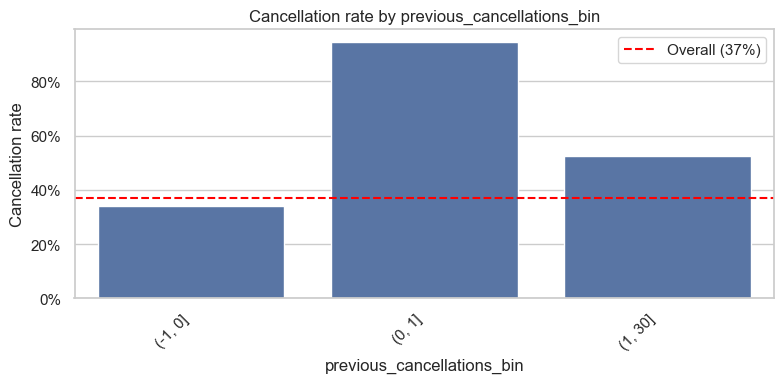

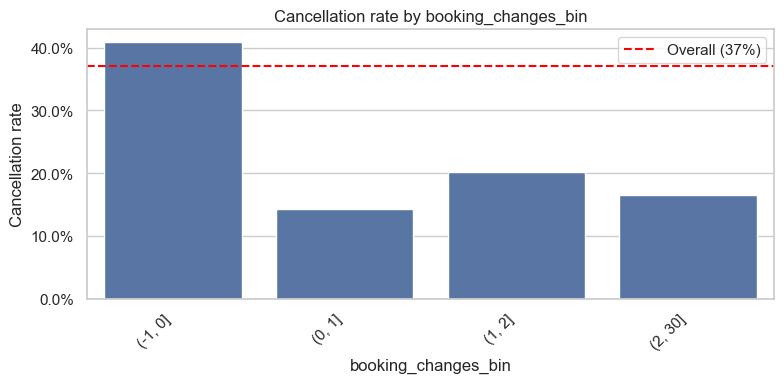

In [10]:
#Numeric drivers: bin then compare cancellation rates
bins = {
    "lead_time": [-1, 7, 30, 90, 180, 365, 800],
    "total_nights": [-1, 0, 1, 3, 7, 14, 100],
    "adr": [-10, 0, 50, 100, 150, 200, 6000],
    "total_of_special_requests": [-1, 0, 1, 2, 5],
    "previous_cancellations": [-1, 0, 1, 30],
    "booking_changes": [-1, 0, 1, 2, 30],
}
for col, b in bins.items():
    d[f"{col}_bin"] = pd.cut(d[col], bins=b)
    cancel_rate_by(f"{col}_bin", name=f"03_{col}")

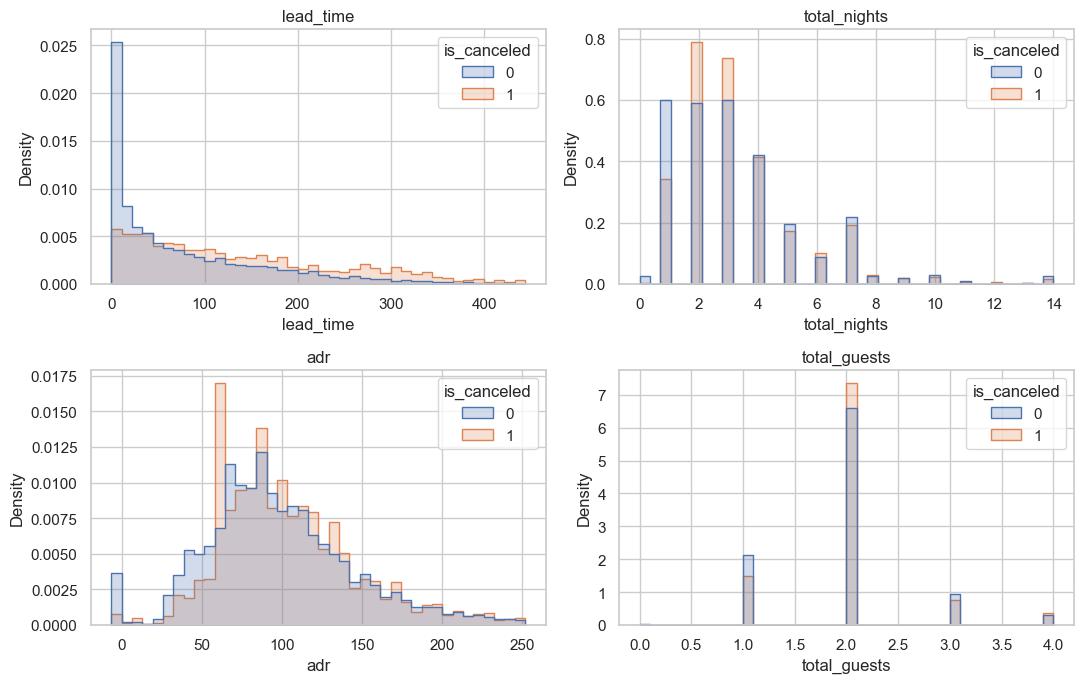

In [11]:
#Distributions: canceled vs not canceled
num_cols = ["lead_time", "total_nights", "adr", "total_guests"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), num_cols):
    clip = d[col].quantile(0.99)           # trim extreme outliers for readability
    sns.histplot(data=d[d[col] <= clip], x=col, hue=TARGET, bins=40,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(col)
save("04_distributions")

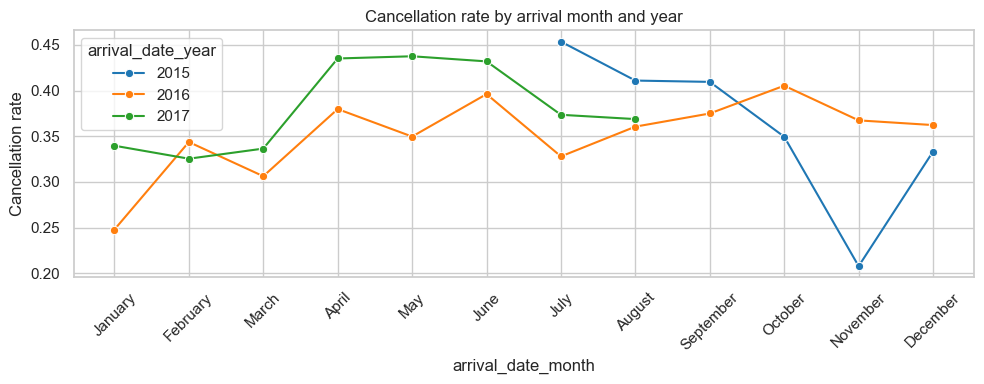

In [12]:
#Cancellation over time (by arrival month and year)
t = (d.groupby(["arrival_date_year", "arrival_date_month"], observed=True)[TARGET]
       .mean().reset_index())
plt.figure(figsize=(10, 4))
sns.lineplot(data=t, x="arrival_date_month", y=TARGET,
             hue="arrival_date_year", marker="o", palette="tab10")
plt.ylabel("Cancellation rate")
plt.xticks(rotation=45)
plt.title("Cancellation rate by arrival month and year")
save("05_time_trend")

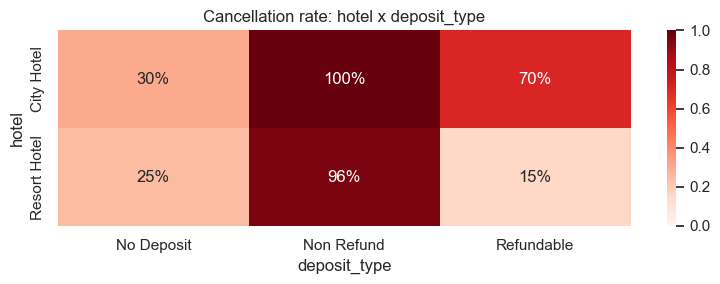

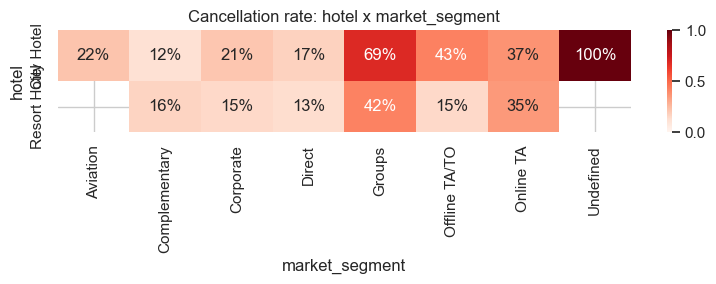

In [13]:
#Two-way view: hotel x deposit type, hotel x market segment
for a, b in [("hotel", "deposit_type"), ("hotel", "market_segment")]:
    pivot = d.pivot_table(index=a, columns=b, values=TARGET, aggfunc="mean")
    plt.figure(figsize=(8, 3))
    sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds", vmin=0, vmax=1)
    plt.title(f"Cancellation rate: {a} x {b}")
    save(f"06_{a}_x_{b}")

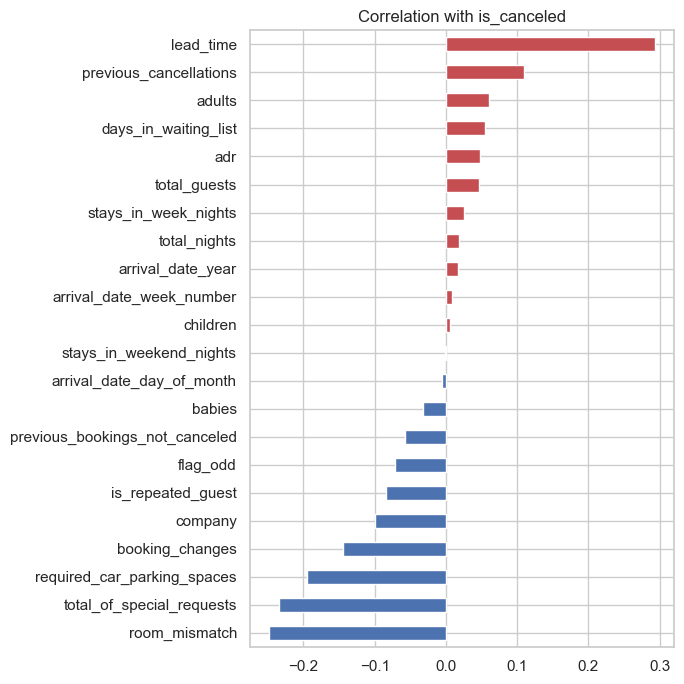

room_mismatch                    -0.248
total_of_special_requests        -0.235
required_car_parking_spaces      -0.195
booking_changes                  -0.144
company                          -0.099
is_repeated_guest                -0.085
flag_odd                         -0.071
previous_bookings_not_canceled   -0.057
babies                           -0.032
arrival_date_day_of_month        -0.006
stays_in_weekend_nights          -0.002
children                          0.005
arrival_date_week_number          0.008
arrival_date_year                 0.017
total_nights                      0.018
stays_in_week_nights              0.025
total_guests                      0.047
adr                               0.048
days_in_waiting_list              0.054
adults                            0.060
previous_cancellations            0.110
lead_time                         0.293
Name: is_canceled, dtype: float64


In [14]:
#Correlation with the target (numeric features)
numeric = d.select_dtypes(include=[np.number]).drop(columns=[c for c in d.columns if c.endswith("_bin")],
                                                    errors="ignore")
corr = numeric.corr()[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(7, 7))
corr.plot(kind="barh", color=np.where(corr > 0, "#C44E52", "#4C72B0"))
plt.title("Correlation with is_canceled")
save("07_correlations")
print(corr.round(3))

In [15]:
#Effect of duplicates and odd records on the cancellation rate
print("Rate, all rows:            ", f"{d[TARGET].mean():.3f}")
print("Rate, drop duplicates:     ", f"{d.drop_duplicates()[TARGET].mean():.3f}")
print("Rate, drop odd records:    ", f"{d[d['flag_odd'] == 0][TARGET].mean():.3f}")

Rate, all rows:             0.370
Rate, drop duplicates:      0.273
Rate, drop odd records:     0.375


In [16]:
#Summary table of key findings (copy into your report)
summary = {
    "Overall rate": rate,
    "City Hotel": d.loc[d.hotel == "City Hotel", TARGET].mean(),
    "Resort Hotel": d.loc[d.hotel == "Resort Hotel", TARGET].mean(),
    "Non Refund deposit": d.loc[d.deposit_type == "Non Refund", TARGET].mean(),
    "Lead time <= 7 days": d.loc[d.lead_time <= 7, TARGET].mean(),
    "Lead time > 365 days": d.loc[d.lead_time > 365, TARGET].mean(),
    "No special requests": d.loc[d.total_of_special_requests == 0, TARGET].mean(),
    "Has previous cancellation": d.loc[d.previous_cancellations > 0, TARGET].mean(),
    "Room mismatch (assigned != reserved)": d.loc[d.room_mismatch == 1, TARGET].mean(),
}
print(pd.Series(summary).map("{:.1%}".format))

Overall rate                            37.0%
City Hotel                              41.7%
Resort Hotel                            27.8%
Non Refund deposit                      99.4%
Lead time <= 7 days                      9.6%
Lead time > 365 days                    67.7%
No special requests                     47.7%
Has previous cancellation               91.6%
Room mismatch (assigned != reserved)     5.4%
dtype: object


# Data pre-processing

In [17]:
#Modeling choices we should agree on (and justify in the report) ---
DROP_DUPLICATES = True       # identical rows in both train and test inflate KNN scores
USE_POST_BOOKING = False     # False = only information known when the booking is made
TEST_SIZE = 0.20


In [18]:
#Load and clean
df = pd.read_csv(DATA_PATH)

# Leakage: these reveal the outcome directly
df = df.drop(columns=["reservation_status", "reservation_status_date"])

if DROP_DUPLICATES:
    before = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Dropped {before - len(df):,} duplicate rows -> {len(df):,} remain")

# Remove clearly invalid records (zero guests, zero nights, impossible ADR)
guests = df["adults"] + df["children"].fillna(0) + df["babies"]
nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
bad = (guests == 0) | (nights == 0) | (df["adr"] <= 0) | (df["adr"] > 1000)
print(f"Removing {bad.sum():,} invalid records")
df = df[~bad].reset_index(drop=True)

Dropped 32,252 duplicate rows -> 87,138 remain
Removing 1,811 invalid records


In [19]:
#Feature engineering
df["children"] = df["children"].fillna(0)
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df["has_agent"] = df["agent"].notna().astype(int)
df["has_company"] = df["company"].notna().astype(int)

# Country has ~170 levels: keep the 10 most common, group the rest.
# (Top countries are chosen from the data; with a very strict workflow you would
# compute this on the training set only. Impact here is negligible.)
top_countries = df["country"].value_counts().head(10).index
df["country_grp"] = np.where(df["country"].isin(top_countries), df["country"], "Other")

numeric_features = [
    "lead_time", "arrival_date_week_number", "total_nights", "total_guests",
    "adr", "total_of_special_requests", "previous_cancellations",
    "previous_bookings_not_canceled", "is_repeated_guest",
    "has_agent", "has_company",
]
categorical_features = [
    "hotel", "arrival_date_month", "meal", "market_segment",
    "distribution_channel", "deposit_type", "customer_type",
    "reserved_room_type", "country_grp",
]

if USE_POST_BOOKING:
    # Finalized after booking or at check-in; including them boosts accuracy
    # but is not realistic for predicting at booking time.
    df["room_mismatch"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)
    numeric_features += ["booking_changes", "days_in_waiting_list",
                         "required_car_parking_spaces", "room_mismatch"]

X = df[numeric_features + categorical_features]
y = df[TARGET]
print("Feature matrix:", X.shape, "| cancellation rate:", round(y.mean(), 3))

Feature matrix: (85327, 20) | cancellation rate: 0.276


# Data split

In [20]:
#Train / test split (stratified so both sets keep the same cancel rate)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=42)

print(f"Train: {X_train.shape[0]:,} rows ({y_train.mean():.3f} canceled)")
print(f"Test:  {X_test.shape[0]:,} rows ({y_test.mean():.3f} canceled)")

Train: 68,261 rows (0.276 canceled)
Test:  17,066 rows (0.276 canceled)


In [21]:
#Preprocessing + KNN pipeline
# KNN is distance-based, so numeric features MUST be scaled, and categoricals
# one-hot encoded. Wrapping everything in a Pipeline means scaling is fit on
# the training folds only (no leakage into validation or test data).
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

knn_pipe = Pipeline([
    ("prep", preprocess),
    ("knn", KNeighborsClassifier(n_jobs=-1)),
])


In [22]:
#Tune k (and weighting) with cross-validation on the TRAINING set
# KNN is slow on large data (every prediction scans all training rows), so we
# tune on a random subsample of the training set, then refit the best setting
# on the FULL training set. Set TUNE_SAMPLE = None to tune on everything
# (much slower; expect many minutes).
TUNE_SAMPLE = 20000
CV_FOLDS = 3

param_grid = {
    "knn__n_neighbors": [5, 11, 21, 41, 81],
    "knn__weights": ["uniform", "distance"],
}
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)

if TUNE_SAMPLE and TUNE_SAMPLE < len(X_train):
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train, train_size=TUNE_SAMPLE,
        stratify=y_train, random_state=42)
else:
    X_tune, y_tune = X_train, y_train

grid = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring="roc_auc",
                    n_jobs=1, refit=False, verbose=1)  # KNN already uses all cores
grid.fit(X_tune, y_tune)

best_params = grid.best_params_
print("\nBest params:", best_params)
print(f"Best CV AUC (on tuning sample): {grid.best_score_:.4f}")

# Refit the best configuration on the full training set
best = knn_pipe.set_params(**best_params).fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best params: {'knn__n_neighbors': 41, 'knn__weights': 'distance'}
Best CV AUC (on tuning sample): 0.8065


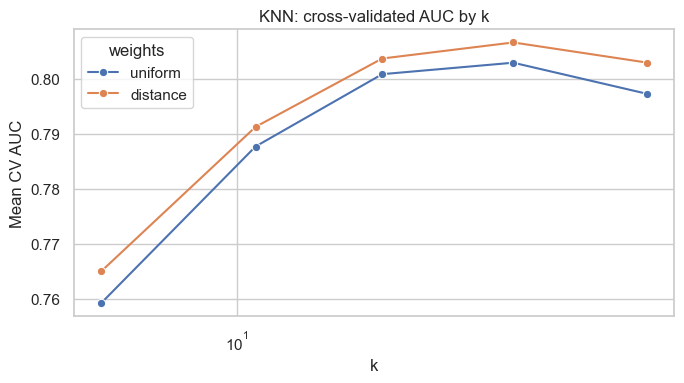

In [23]:
#Plot: validation AUC vs k
res = pd.DataFrame(grid.cv_results_)
res["k"] = res["param_knn__n_neighbors"].astype(int)
res["weights"] = res["param_knn__weights"]

plt.figure(figsize=(7, 4))
sns.lineplot(data=res, x="k", y="mean_test_score", hue="weights", marker="o")
plt.xscale("log")
plt.ylabel("Mean CV AUC")
plt.title("KNN: cross-validated AUC by k")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_k_tuning.png", dpi=150)
plt.show()

Test AUC: 0.8326

              precision    recall  f1-score   support

Not canceled      0.823     0.925     0.871     12350
    Canceled      0.710     0.480     0.573      4716

    accuracy                          0.802     17066
   macro avg      0.767     0.703     0.722     17066
weighted avg      0.792     0.802     0.789     17066



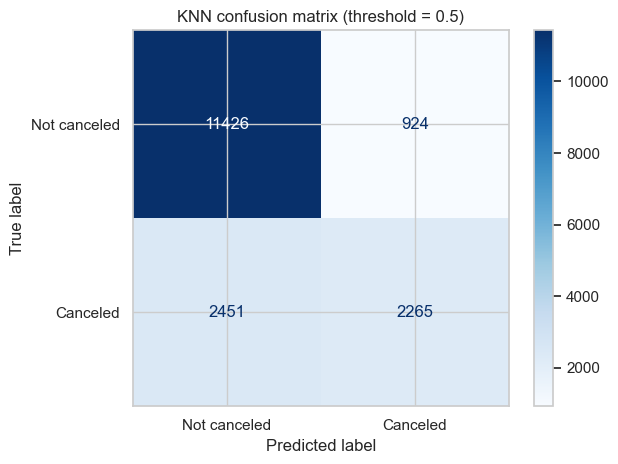

In [24]:
#Evaluate the best model on the held-out TEST set
proba = best.predict_proba(X_test)[:, 1]
pred_default = (proba >= 0.5).astype(int)

# Preserve KNN evaluation results before later cells overwrite variables.
knn_y_test = y_test.copy()
knn_proba = proba.copy()

print(f"Test AUC: {roc_auc_score(y_test, proba):.4f}\n")
print(classification_report(y_test, pred_default,
                            target_names=["Not canceled", "Canceled"], digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_default, display_labels=["Not canceled", "Canceled"], cmap="Blues")
plt.title("KNN confusion matrix (threshold = 0.5)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_confusion_matrix.png", dpi=150)
plt.show()

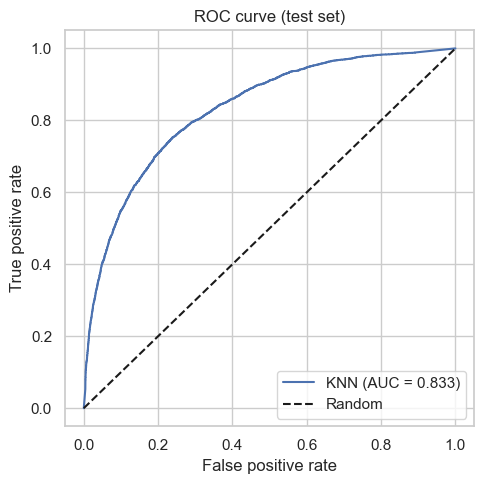

In [25]:
#ROC curve
fpr, tpr, _ = roc_curve(y_test, proba)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"KNN (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (test set)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_roc.png", dpi=150)
plt.show()

In [26]:
#Threshold exploration (recall vs precision trade-off)
rows = []
for t in np.arange(0.2, 0.8, 0.1):
    p = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"threshold": round(t, 1),
                 "precision": tp / (tp + fp) if (tp + fp) else np.nan,
                 "recall": tp / (tp + fn),
                 "flagged_%": p.mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 threshold  precision  recall  flagged_%
       0.2      0.439   0.877      0.552
       0.3      0.541   0.756      0.386
       0.4      0.629   0.622      0.273
       0.5      0.714   0.480      0.186
       0.6      0.782   0.338      0.119
       0.7      0.845   0.211      0.069
       0.8      0.877   0.119      0.038


## Additional Model Comparison: Logistic Regression, Decision Tree, + Random Forest

In [27]:
## Prep data + define target/predictors

# Reload the dataset to ensure the columns exist
df = pd.read_csv(DATA_PATH)

df = df.drop(columns=[
    "reservation_status",
    "reservation_status_date"
], errors="ignore")

#Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

#Remove records with no guests, no nights, or unusual ADR
guests = (
    df["adults"] +
    df["children"].fillna(0) +
    df["babies"]
)

nights = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

bad = (
    (guests == 0) |
    (nights == 0) |
    (df["adr"] <= 0) |
    (df["adr"] > 1000)
)

df = df[~bad].reset_index(drop=True)

# Fill missing children values
df["children"] = df["children"].fillna(0)

#Create derived features
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

df["total_guests"] = (
    df["adults"] +
    df["children"] +
    df["babies"]
)

df["has_agent"] = df["agent"].notna().astype(int)
df["has_company"] = df["company"].notna().astype(int)

# Group uncommon countries together
top_countries = df["country"].value_counts().head(10).index

df["country_grp"] = df["country"].where(
    df["country"].isin(top_countries),
    "Other"
)

print("Modeling dataset:", df.shape)
print("Cancellation rate:", round(df["is_canceled"].mean(), 3))

Modeling dataset: (85327, 35)
Cancellation rate: 0.276


In [28]:
## Define target and predictors

TARGET = "is_canceled"

# Features to use
numeric_features = [
    "lead_time",
    "arrival_date_week_number",
    "total_nights",
    "total_guests",
    "adr",
    "total_of_special_requests",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "is_repeated_guest",
    "has_agent",
    "has_company"
]

categorical_features = [
    "hotel",
    "arrival_date_month",
    "meal",
    "market_segment",
    "distribution_channel",
    "deposit_type",
    "customer_type",
    "reserved_room_type",
    "country_grp"
]

X = df[numeric_features + categorical_features].copy()
y = df[TARGET].astype(int)

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (85327, 20)
Target shape: (85327,)


In [29]:
## Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

In [30]:
## Identify categorical columns

cat_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns

X_train = X_train.copy()
X_test = X_test.copy()

## Fill missing categorical values

X_train[cat_cols] = X_train[cat_cols].fillna("Missing")
X_test[cat_cols] = X_test[cat_cols].fillna("Missing")

## Convert categorical columns into numeric indicators

X_train = pd.get_dummies(
    X_train, drop_first=True, dtype=int
)

X_test = pd.get_dummies(
    X_test, drop_first=True, dtype=int
)

## Make sure training and testing have the same columns

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

## Fill remaining missing values

imputer = SimpleImputer(strategy="median")

## Impute both datasets
X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

## Missing values check
print("Training missing values:", X_train.isna().sum().sum())
print("Testing missing values:", X_test.isna().sum().sum())

Training missing values: 0
Testing missing values: 0


In [31]:
def compare_models(models, X_train, X_test, y_train, y_test):
    results = []

    for name, model in models.items():
        model.fit(X_train, y_train)

        predictions = model.predict(X_test)
        probabilities = model.predict_proba(X_test)[:, 1]

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_test, probabilities)
        })

    return pd.DataFrame(results).set_index("Model")

In [32]:
## Define models

models = {
    "Logistic Regression": Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000)),
]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        random_state=123
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        random_state=123,
        n_jobs=-1
    )
}

In [33]:
results = compare_models(
    models, X_train, X_test, y_train, y_test
)

results.sort_values("ROC-AUC", ascending=False).round(3)

,Accuracy,Precision,Recall,ROC-AUC
Model,,,,
Random Forest,0.805,0.734,0.464,0.859
Decision Tree,0.797,0.670,0.525,0.837
Logistic Regression,0.778,0.662,0.405,0.807


In [34]:
## Compare classification thresholds

rf = models["Random Forest"]
cancel_prob = rf.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.4, 0.5]:
    cancel_pred = (cancel_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision_score(y_test, cancel_pred, zero_division=0):.3f} | "
        f"Recall: {recall_score(y_test, cancel_pred, zero_division=0):.3f}"
    )

Threshold: 0.3 | Precision: 0.558 | Recall: 0.793
Threshold: 0.4 | Precision: 0.660 | Recall: 0.594
Threshold: 0.5 | Precision: 0.734 | Recall: 0.464


## Model Performance Comparison

The table below compares precision, recall, F1, and ROC-AUC at a
classification threshold of 0.5. Recall measures the proportion of
canceled bookings identified, while precision measures how many flagged
bookings actually canceled. F1 summarizes the balance between precision
and recall. ROC-AUC measures how well each model ranks canceled bookings
above bookings that were not canceled across thresholds.

This comparison is preliminary: KNN uses a different train/test split
from the other three models. All models must be evaluated on the same
held-out observations before final selection. Threshold selection should
use validation data, with the test set reserved for final evaluation.

In [35]:
# Compare models using their saved test predictions
# KNN currently uses a different test split, so this comparison is preliminary
comparison_rows = []

model_predictions = {
    "KNN": (knn_y_test, knn_proba),
}

for name, model in models.items():
    model_predictions[name] = (
        y_test,
        model.predict_proba(X_test)[:, 1],
    )

for name, (actual, probabilities) in model_predictions.items():
    predicted = (probabilities >= 0.5).astype(int)

    comparison_rows.append({
        "Model": name,
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0),
        "ROC-AUC": roc_auc_score(actual, probabilities),
    })

model_comparison = pd.DataFrame(comparison_rows).set_index("Model")
model_comparison.sort_values("ROC-AUC", ascending=False).round(3)

,Precision,Recall,F1,ROC-AUC
Model,,,,
Random Forest,0.734,0.464,0.569,0.859
Decision Tree,0.667,0.528,0.589,0.837
KNN,0.710,0.480,0.573,0.833
Logistic Regression,0.662,0.405,0.503,0.807


## Decision Tree Analysis

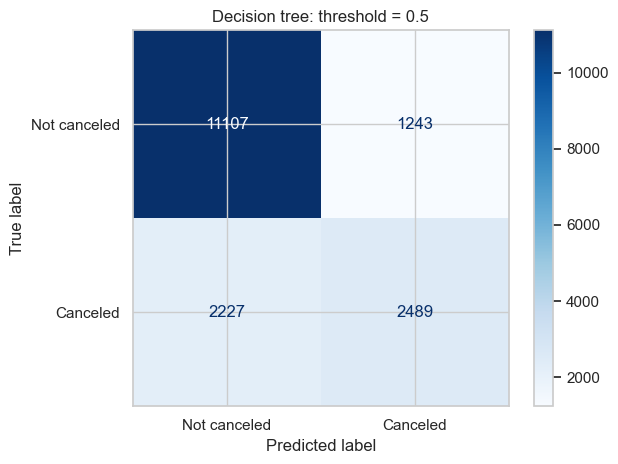

              precision    recall  f1-score   support

Not canceled      0.833     0.899     0.865     12350
    Canceled      0.667     0.528     0.589      4716

    accuracy                          0.797     17066
   macro avg      0.750     0.714     0.727     17066
weighted avg      0.787     0.797     0.789     17066

ROC-AUC: 0.837


In [39]:
# Evaluate the selected decision tree at threshold 0.5
evaluation_model = models["Decision Tree"]
evaluation_threshold = 0.5

evaluation_proba = evaluation_model.predict_proba(X_test)[:, 1]
evaluation_pred = (
    evaluation_proba >= evaluation_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    evaluation_pred,
    labels=[0, 1],
    display_labels=["Not canceled", "Canceled"],
    cmap="Blues",
)
plt.title("Decision tree: threshold = 0.5")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    evaluation_pred,
    target_names=["Not canceled", "Canceled"],
    digits=3,
))
print(f"ROC-AUC: {roc_auc_score(y_test, evaluation_proba):.3f}")

In [41]:
# Recover hotel types using the preserved test-row indices

evaluation = pd.DataFrame({
    "hotel": df.loc[X_test.index, "hotel"],
    "actual": y_test,
    "predicted": evaluation_pred,
    "probability": evaluation_proba,
})

hotel_results = []

for hotel, group in evaluation.groupby("hotel"):
    tn, fp, fn, tp = confusion_matrix(
        group["actual"],
        group["predicted"],
        labels=[0, 1],
    ).ravel()

    hotel_results.append({
        "Hotel": hotel,
        "Bookings": len(group),
        "Cancellations caught": tp,
        "Cancellations missed": fn,
        "False alarms": fp,
        "Precision": precision_score(
            group["actual"], group["predicted"], zero_division=0
        ),
        "Recall": recall_score(
            group["actual"], group["predicted"], zero_division=0
        ),
        "F1": f1_score(
            group["actual"], group["predicted"], zero_division=0
        ),
    })

hotel_evaluation = pd.DataFrame(hotel_results).set_index("Hotel")
hotel_evaluation.round(3)

,Bookings,Cancellations caught,Cancellations missed,False alarms,Precision,Recall,F1
Hotel,,,,,,,
City Hotel,10430,1681,1490,842,0.666,0.530,0.590
Resort Hotel,6636,808,737,401,0.668,0.523,0.587


### Evaluation Findings

At a threshold of 0.5, the decision tree achieved 52.8% cancellation
recall, 66.7% precision, and an F1 score of 0.589. Its ROC-AUC was
0.837, with overall accuracy of 79.7%.

The model identified slightly more than half of actual cancellations,
while approximately two-thirds of flagged bookings were cancellations.
Compared with random forest at the same threshold, it achieved higher
recall and F1 but lower precision, supporting its selection when
cancellation detection takes priority.

However, it still missed 47.2% of cancellations, and approximately
one-third of flagged bookings were false alarms. It can help prioritize
reservation follow-up, but its predictions provide incomplete coverage
and do not establish that follow-up would prevent cancellations.

Performance was similar across hotel types. City Hotel recall was
53.0%, compared with 52.3% for Resort Hotel; precision was 66.6%
and 66.8%, respectively. The model caught 1,681 cancellations at
City Hotel and 808 at Resort Hotel, while missing 1,490 and 737.
The similar precision, recall, and F1 scores suggest that the overall
results do not mask a large performance gap between the two hotels
in this test sample.

In [42]:
## Exploratory Random Forest Threshold Analysis
rf_probabilities = models["Random Forest"].predict_proba(X_test)[:, 1]
workload_rows = []

for threshold in [0.3, 0.4, 0.5]:
    predictions = (rf_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    workload_rows.append({
        "Threshold": threshold,
        "Bookings flagged": tp + fp,
        "Flagged (%)": 100 * predictions.mean(),
        "Cancellations caught": tp,
        "Cancellations missed": fn,
        "False alarms": fp,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
    })

workload_comparison = pd.DataFrame(workload_rows).set_index("Threshold")
workload_comparison.round(3)

,Bookings flagged,Flagged (%),Cancellations caught,Cancellations missed,False alarms,Precision,Recall
Threshold,,,,,,,
0.3,6703,39.277,3741,975,2962,0.558,0.793
0.4,4246,24.880,2802,1914,1444,0.660,0.594
0.5,2981,17.467,2188,2528,793,0.734,0.464


### Cancellation Detection and Follow-Up Workload

Lowering the random forest threshold from 0.5 to 0.3 increased
cancellations identified from 2,188 to 3,741, raising recall from
46.4% to 79.3%. This required flagging 6,703 bookings instead of
2,981 (39.3% of the test set rather than 17.5%).

The additional 3,722 flags captured 1,553 more cancellations and
introduced 2,169 additional false alarms. That amounts to roughly
2.4 additional reviews per additional cancellation identified,
assuming every flagged booking receives one review.

A threshold of 0.4 offers an intermediate workload: 4,246 bookings
flagged, 59.4% recall, and 66.0% precision. The appropriate threshold
depends on how many reservations staff can review and the relative
costs of missed cancellations and unnecessary contact.

These results support considering a lower threshold for a low-cost
confirmation workflow. They do not establish an optimal threshold
or show that follow-up prevents cancellation. Threshold selection
requires validation data, followed by prospective evaluation of
the workflow.

## Model Brief

We compared logistic regression, K-nearest neighbors (KNN), a decision
tree, and random forest to predict booking cancellations. Logistic
regression provided an interpretable linear baseline, KNN assessed
similarity between booking profiles, and the tree-based models captured
nonlinear relationships and feature interactions.

KNN tuning used three-fold stratified cross-validation on 20,000
training records and selected 41 neighbors with distance weighting.
The other models used fixed hyperparameters. Scaling the logistic
regression inputs and increasing its iteration limit resolved its
initial convergence warning.

### Findings and Model Choice

Random forest achieved the highest reported ROC-AUC (0.859), followed
by decision tree (0.837) and logistic regression (0.807) on the same
test split. KNN achieved 0.833 on a different split, limiting direct
comparison. The tree-based models outperformed the linear baseline
in ranking cancellation risk.

At a threshold of 0.5, the decision tree achieved the highest reported
recall (52.8%) and F1 (0.589), with precision of 66.7%. Random forest
provided higher precision (73.4%) but lower recall (46.4%). We selected
the decision tree because identifying more cancellations, while
retaining a reasonable balance between precision and recall, better
matches the project's screening objective.

Random forest threshold exploration showed that higher recall is
possible with additional false alarms and follow-up workload. Those
results remain exploratory and do not establish a validated operating
threshold or a fair comparison with similarly adjusted alternatives.

### Limitations and Next Steps

Model selection used reported test performance rather than a separate
validation comparison, so the selected model's results may be optimistic.
KNN's different split further limits comparisons across all four models.
Country grouping was determined before splitting, and duplicate and
outlier exclusions may change the population represented by the analysis.
Predictor availability at booking time also requires confirmation.

The next step is to use consistent evaluation partitions, learn
preprocessing from training data only, and use validation results for
hyperparameter, model, and threshold selection. Further work should
assess performance on later bookings and probability calibration.
Results from two hotels in 2015-2017 may not generalize to current
operations.

A pilot should measure whether targeted follow-up improves outcomes
enough to justify its workload. Predicting cancellation does not
establish that an intervention prevents it or recovers revenue.

## Final Model Selection and Conclusion

We select the decision tree at a threshold of 0.5 as the preferred
configuration among those evaluated at the default threshold. It
achieved 52.8% cancellation recall, 66.7% precision, and an F1 score
of 0.589. This favors identifying more cancellations while maintaining
a better precision–recall balance than the other reported default
configurations.

Random forest achieved stronger ROC-AUC and precision, making it a
credible alternative when ranking reservations or limiting false
alarms takes priority. Our selection reflects the project's emphasis
on cancellation detection rather than ROC-AUC alone.

The decision tree still misses approximately 47% of cancellations,
and roughly one-third of its flagged bookings are false alarms.
It could support reservation review, but should not be the sole
basis for cancellation-management decisions. Its operational value
depends on follow-up costs, staff capacity, and whether intervention
changes guest behavior.

This selection requires confirmation through validation-based model
comparison. Future work should evaluate later booking periods and
test the follow-up process in a pilot before making claims about
reduced cancellations or revenue benefits.